###                                                            
#                                                           ENVIRONMENT SETUP

In [8]:
import os
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
#installing tensorflow
!pip install tensorflow
!pip install numpy

In [10]:
import tensorflow as tf
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt

IMPORTING DATA SET TO TENSORFLOW DATA SET OBJECT

In [11]:
#function is used to create a dataset from image
dataset_path = "/content/drive/MyDrive/DATASET Potato"
#files stored in a directory structure. It automatically labels the data based on the subdirectories' names.
Potato_Leaf_Disease = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,#The directory path from which the images will be loaded.
     seed=123,#This parameter sets the random seed for shuffling the data. It ensures reproducibility of the results if the code is run multiple times.
     shuffle=True,#This parameter indicates whether to shuffle the data.
     image_size=(256,256),#This parameter specifies the size to which the images will be resized.
     batch_size=32#This parameter determines the number of images to include in each batch of the dataset
)

Found 3077 files belonging to 7 classes.


                                                            
#                                                            EXPLORATARY DATA ANALYSIS

In [12]:
ClassNames = Potato_Leaf_Disease.class_names # set ClassNames object to detect names of all classes
ClassNames

['Bacteria-20261102T140206Z-1-001',
 'Fungi-20261102T140625Z-1-001',
 'Healthy-20261102T140918Z-1-001',
 'Nematode-20261102T142130Z-1-001',
 'Pest-20261102T145100Z-1-001',
 'Phytopthora-20261102T145243Z-1-001',
 'Virus-20261102T173511Z-1-001']

In [13]:
for image_batch, labels_batch in Potato_Leaf_Disease.take(1):
    print(image_batch.shape)
    print(labels_batch.numpy())

(32, 256, 256, 3)
[0 0 3 1 2 5 4 1 6 6 1 4 0 6 4 5 6 1 4 1 6 5 4 4 5 0 5 1 1 1 6 6]


Visualizing the Available images

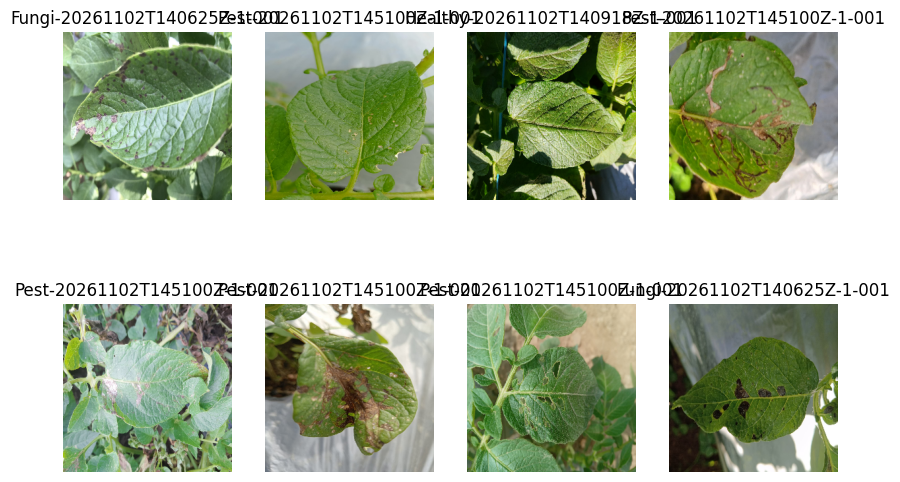

In [14]:
plt.figure(figsize=(10, 10))
for image_batch, labels_batch in Potato_Leaf_Disease.take(1):
    for i in range(8):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(ClassNames[labels_batch[i]])
        plt.axis("off")

# **Details about each Potato disease**


In [15]:
import matplotlib.pyplot as plt
import math

def plot_images(dataset, class_name, num_images=25, nrows=5, ncols=5):
    # Get the index of the class
    class_index = dataset.class_names.index(class_name)

    # Calculate the total number of images to plot, limited by num_images
    total_images_to_plot = min(num_images, nrows * ncols)

    fig = plt.figure(figsize=(2 * ncols, 2 * nrows))
    fig.suptitle(f'Sample images for class: {class_name}', fontsize=16)

    image_count = 0
    for images, labels in dataset:
        class_images = images[labels.numpy() == class_index]
        for image in class_images:
            if image_count < total_images_to_plot:
                ax = plt.subplot(nrows, ncols, image_count + 1)
                plt.imshow(image.numpy().astype("uint8"))
                plt.title(class_name)
                plt.axis("off")
                image_count += 1
            else:
                plt.tight_layout()
                plt.show()
                return
    plt.tight_layout()
    plt.show()


# **Bacterial Disease Description**



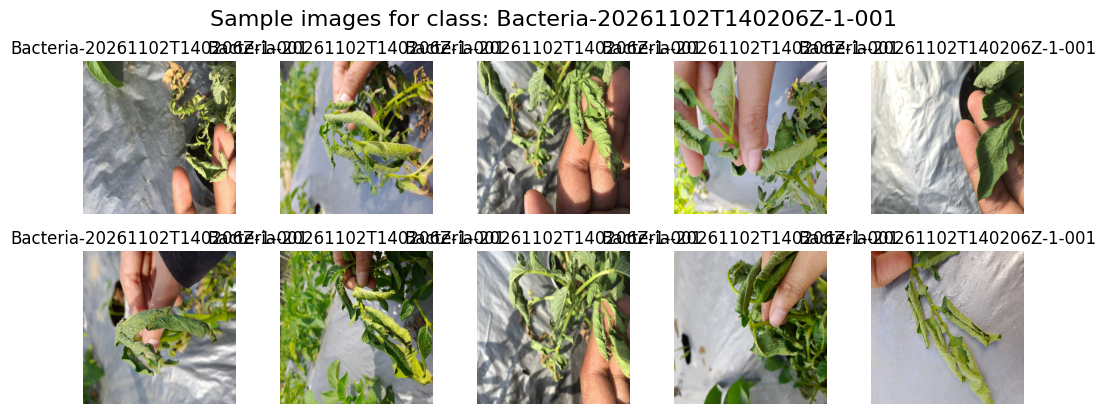

In [17]:
plot_images(Potato_Leaf_Disease, 'Bacteria-20261102T140206Z-1-001', num_images=10, nrows=5, ncols=5)

# **Fungal Disease Description**


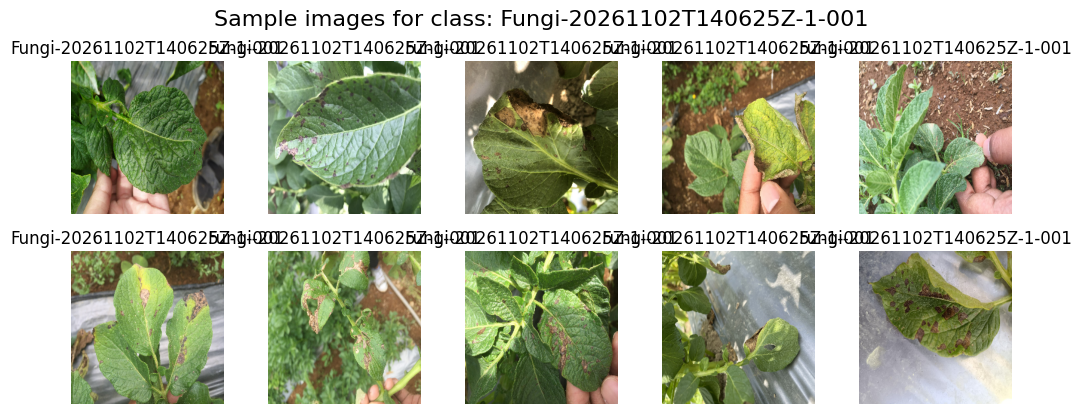

In [19]:
plot_images(Potato_Leaf_Disease, 'Fungi-20261102T140625Z-1-001', num_images=10, nrows=5, ncols=5)

# **Phytophthora Disease Description**

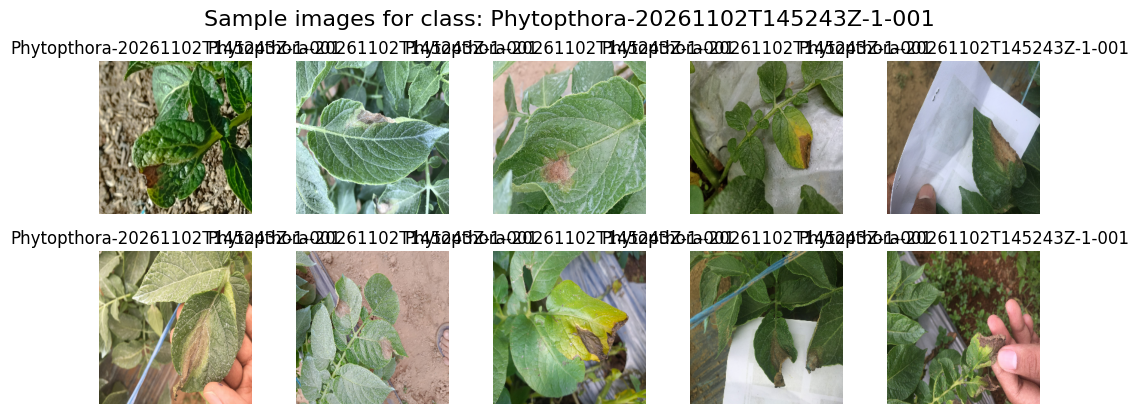

In [21]:
plot_images(Potato_Leaf_Disease, 'Phytopthora-20261102T145243Z-1-001', num_images=10, nrows=5, ncols=5)

# **Nematode Disease Description**

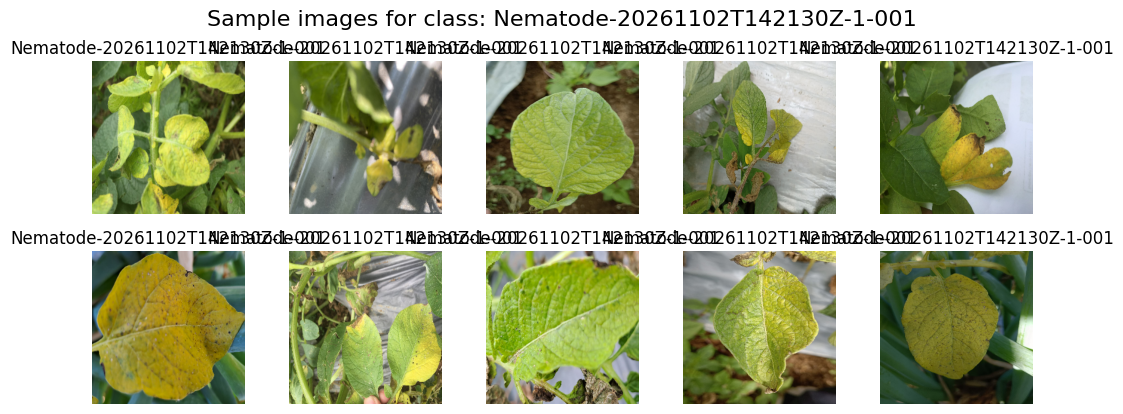

In [23]:
plot_images(Potato_Leaf_Disease, 'Nematode-20261102T142130Z-1-001', num_images=10, nrows=5, ncols=5)

# **Pest Disease Description**

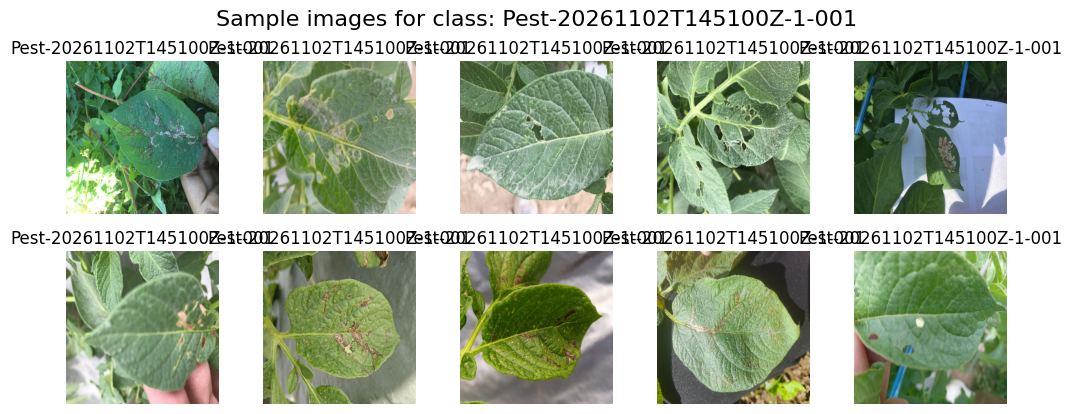

In [25]:
plot_images(Potato_Leaf_Disease, 'Pest-20261102T145100Z-1-001', num_images=10, nrows=5, ncols=5)

# **Virus Disease Description**

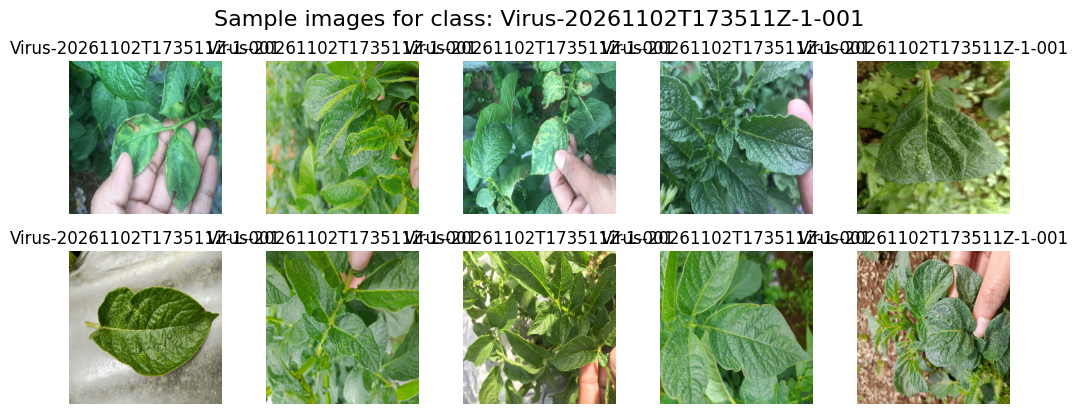

In [26]:
plot_images(Potato_Leaf_Disease, 'Virus-20261102T173511Z-1-001', num_images=10, nrows=5, ncols=5)

# **Healthy Plant Description**

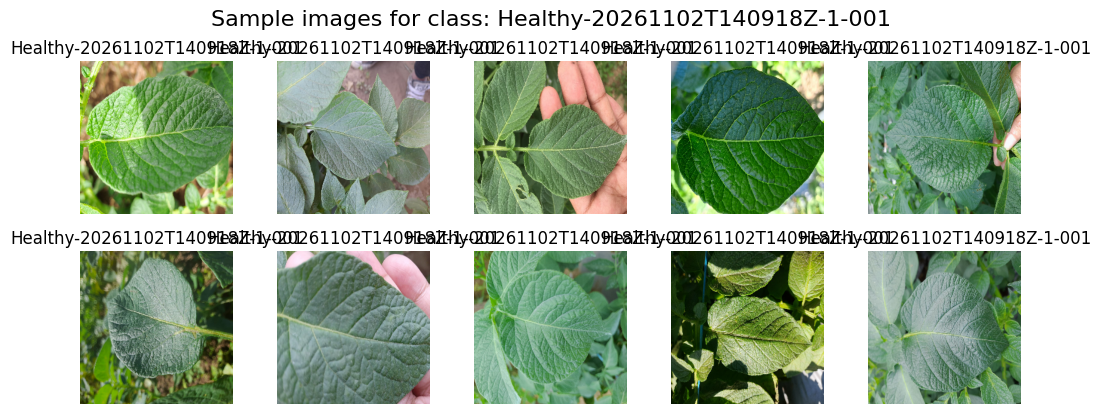

In [27]:
plot_images(Potato_Leaf_Disease, 'Healthy-20261102T140918Z-1-001', num_images=10, nrows=5, ncols=5)

# PREPROCESSING


# 1. Splitting the Dataset
Before building the model, the dataset needs to be split into training, validation, and test sets.

In [28]:
def get_dataset_partitions(ds, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=100000):
    ds_size = len(ds)

    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)

    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)

    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)

    return train_ds, val_ds, test_ds

train_ds, val_ds, test_ds = get_dataset_partitions(Potato_Leaf_Disease)

print(len(train_ds), len(val_ds), len(test_ds))

77 9 11


# 2. Optimising Dataset Performance
Caching and prefetching are used to speed up training by reducing I/O bottlenecks.

In [29]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

# 3. Preprocessing: Resizing, Rescaling & Data Augmentation

Data augmentation artificially increases training data diversity by applying random transformations, helping reduce overfitting given the moderate dataset size (3,076 images across 7 classes).

In [30]:
ClassNames = Potato_Leaf_Disease.class_names # set ClassNames object to detect names of all classes
ClassNames

['Bacteria-20261102T140206Z-1-001',
 'Fungi-20261102T140625Z-1-001',
 'Healthy-20261102T140918Z-1-001',
 'Nematode-20261102T142130Z-1-001',
 'Pest-20261102T145100Z-1-001',
 'Phytopthora-20261102T145243Z-1-001',
 'Virus-20261102T173511Z-1-001']

In [31]:
len(Potato_Leaf_Disease)

97

In [32]:
train_size = 0.8
len(Potato_Leaf_Disease)*train_size

77.60000000000001

In [33]:
train_ds = Potato_Leaf_Disease.take(77)
len(train_ds)

77

In [34]:
test_ds = Potato_Leaf_Disease.skip(77)
len(test_ds)

20

In [35]:
val_size=0.1
len(Potato_Leaf_Disease)*val_size

9.700000000000001

In [36]:
val_ds = test_ds.take(20)
len(val_ds)

20

In [37]:
IMAGE_SIZE = 256
CHANNELS = 3

resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1.0/255)
])

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])

# 4. Building the CNN Model

Architecture rationale

  >Six convolutional blocks progressively extract low-level (edges, colour) to high-level (lesion patterns, texture) features from the leaf images.

  >MaxPooling layers reduce spatial dimensions, controlling computational cost and helping the model generalise.

  >A Dropout layer (0.3) is included before the final dense layer to reduce overfitting.

  >The final Dense layer uses softmax activation with 7 units, corresponding to the 7 disease classes.

In [38]:
n_classes = 7
BATCH_SIZE = 32

model = models.Sequential([
    resize_and_rescale,
    data_augmentation,

    layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(n_classes, activation='softmax'),
])

model.build(input_shape=(BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (32, 254, 254, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (32, 127, 127, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (32, 125, 125, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (32, 62, 62, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (32, 60, 60, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (32, 30, 30, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (32, 28, 28, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (32, 14, 14, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (32, 12, 12, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (32, 6, 6, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (32, 4, 4, 64)         │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (32, 2, 2, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (32, 256)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (32, 64)               │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (32, 64)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (32, 7)                │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 184,007 (718.78 KB)

 Trainable params: 184,007 (718.78 KB)

 Non-trainable params: 0 (0.00 B)

# 5. Compiling the Model

Adam optimizer is used for efficient adaptive gradient-based learning.
Sparse Categorical Crossentropy is appropriate since labels are integer-encoded (0–6) rather than one-hot encoded.

In [39]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# 6. Training the Model

In [40]:
EPOCHS = 10

history = model.fit(
    train_ds,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    validation_data=val_ds
)

Epoch 1/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 889s 12s/step - accuracy: 0.2200 - loss: 1.8280 - val_accuracy: 0.2414 - val_loss: 1.8086
Epoch 2/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 54s 702ms/step - accuracy: 0.2338 - loss: 1.7919 - val_accuracy: 0.2414 - val_loss: 1.8183
Epoch 3/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 52s 674ms/step - accuracy: 0.2411 - loss: 1.7891 - val_accuracy: 0.2382 - val_loss: 1.8252
Epoch 4/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 53s 695ms/step - accuracy: 0.2537 - loss: 1.7859 - val_accuracy: 0.2659 - val_loss: 1.7894
Epoch 5/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 64s 835ms/step - accuracy: 0.2979 - loss: 1.7256 - val_accuracy: 0.2675 - val_loss: 1.7390
Epoch 6/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 54s 703ms/step - accuracy: 0.2910 - loss: 1.6850 - val_accuracy: 0.3034 - val_loss: 1.7175
Epoch 7/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 52s 676ms/step - accuracy: 0.3149 - loss: 1.6624 - val_accuracy: 0.3246 - val_loss: 1.6611
Epoch 8/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 66s 860ms/step - accuracy: 0.3129 - loss: 1.6530 - val_accur

# 7. Evaluating on the Test Set

In [41]:
scores = model.evaluate(test_ds)
print("Custom CNN Test Loss:", scores[0])
print("Custom CNN Test Accuracy:", scores[1])

20/20 ━━━━━━━━━━━━━━━━━━━━ 29s 310ms/step - accuracy: 0.3573 - loss: 1.5762
Custom CNN Test Loss: 1.5761674642562866
Custom CNN Test Accuracy: 0.3572593927383423


# 8. Plot Training Curves

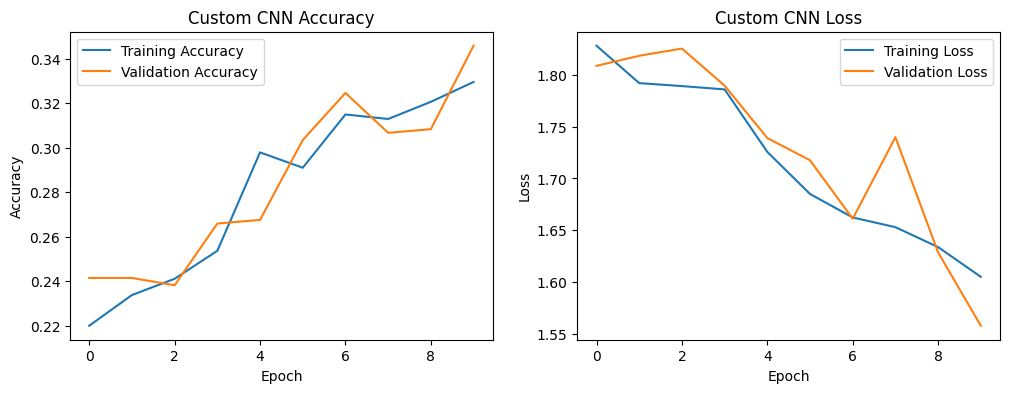

In [42]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Custom CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend()
plt.title('Custom CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.show()

# Save Model

In [43]:
import os
from google.colab import drive

# Mount your Google Drive
drive.mount('/content/drive', force_remount=True)

# Use a DIFFERENT folder for saved models (not the dataset folder!)
model_dir = '/content/drive/MyDrive/Potato_Leaf_Disease_Models'

# Check if the directory exists, create if not
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Get the latest model version safely (ignore non-numeric folder/file names)
existing_versions = [
    int(i.split('_v')[-1].split('.keras')[0])
    for i in os.listdir(model_dir)
    if i.startswith('model_v') and i.split('_v')[-1].split('.keras')[0].isdigit()
]
model_version = max(existing_versions + [0]) + 1

# Save the model in the native Keras format
model.save(os.path.join(model_dir, f"model_v{model_version}.keras"))

print(f"Model saved as model_v{model_version}.keras in {model_dir}")

Mounted at /content/drive
Model saved as model_v1.keras in /content/drive/MyDrive/Potato_Leaf_Disease_Models


# VGG16 Model

# VGG16 Transfer Learning Model

In [44]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

IMAGE_SIZE = 256
CHANNELS = 3
n_classes = 7

# Load VGG16 pretrained on ImageNet, without the top classification layers
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
)

# Freeze the base model so pretrained weights aren't updated during initial training
base_model.trainable = False

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


# 2. Preprocessing Layer for VGG16

In [45]:
vgg_preprocess = tf.keras.layers.Lambda(preprocess_input)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])

# 3. Build the Full Model

In [46]:
vgg16_model = models.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    data_augmentation,
    vgg_preprocess,

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(n_classes, activation='softmax'),
])

vgg16_model.build(input_shape=(None, IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
vgg16_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_1 (Resizing)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_3 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 8, 8, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,255 (56.39 MB)

 Trainable params: 66,567 (260.03 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

# 4. Compile the Model

In [47]:
vgg16_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# 5. Train

In [48]:
EPOCHS = 10

history_vgg16 = vgg16_model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    verbose=1
)

Epoch 1/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 58s 714ms/step - accuracy: 0.2224 - loss: 3.5474 - val_accuracy: 0.3687 - val_loss: 2.1557
Epoch 2/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 54s 700ms/step - accuracy: 0.2792 - loss: 2.5049 - val_accuracy: 0.4160 - val_loss: 1.7413
Epoch 3/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 54s 702ms/step - accuracy: 0.3105 - loss: 2.0664 - val_accuracy: 0.4584 - val_loss: 1.5460
Epoch 4/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 54s 709ms/step - accuracy: 0.3531 - loss: 1.8128 - val_accuracy: 0.5073 - val_loss: 1.4106
Epoch 5/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 51s 667ms/step - accuracy: 0.3782 - loss: 1.6677 - val_accuracy: 0.4943 - val_loss: 1.3735
Epoch 6/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 54s 702ms/step - accuracy: 0.4083 - loss: 1.5895 - val_accuracy: 0.5432 - val_loss: 1.3203
Epoch 7/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 54s 698ms/step - accuracy: 0.4257 - loss: 1.5366 - val_accuracy: 0.5285 - val_loss: 1.2909
Epoch 8/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 81s 684ms/step - accuracy: 0.4286 - loss: 1.5003 - val_accu

# 6. Fine-Tune

In [49]:
# Unfreeze the base model
base_model.trainable = True

# Freeze all layers except the last 4 (last conv block)
for layer in base_model.layers[:-4]:
    layer.trainable = False

# Recompile with a much lower learning rate for fine-tuning
vgg16_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

fine_tune_epochs = 5
total_epochs = EPOCHS + fine_tune_epochs

history_fine_tune = vgg16_model.fit(
    train_ds,
    epochs=total_epochs,
    initial_epoch=history_vgg16.epoch[-1] + 1,
    validation_data=val_ds,
    verbose=1
)

Epoch 11/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 68s 847ms/step - accuracy: 0.4935 - loss: 1.3218 - val_accuracy: 0.6085 - val_loss: 1.0453
Epoch 12/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 55s 714ms/step - accuracy: 0.5686 - loss: 1.1594 - val_accuracy: 0.6199 - val_loss: 1.0186
Epoch 13/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 55s 717ms/step - accuracy: 0.6177 - loss: 1.0677 - val_accuracy: 0.6607 - val_loss: 0.9338
Epoch 14/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 65s 844ms/step - accuracy: 0.6331 - loss: 1.0013 - val_accuracy: 0.6770 - val_loss: 0.8754
Epoch 15/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 56s 729ms/step - accuracy: 0.6567 - loss: 0.9451 - val_accuracy: 0.7129 - val_loss: 0.8421


# 7. Evaluate on Test Set

In [ ]:
scores = vgg16_model.evaluate(test_ds)
print("VGG16 Test Loss:", scores[0])
print("VGG16 Test Accuracy:", scores[1])

# 8. Plot Training Curves

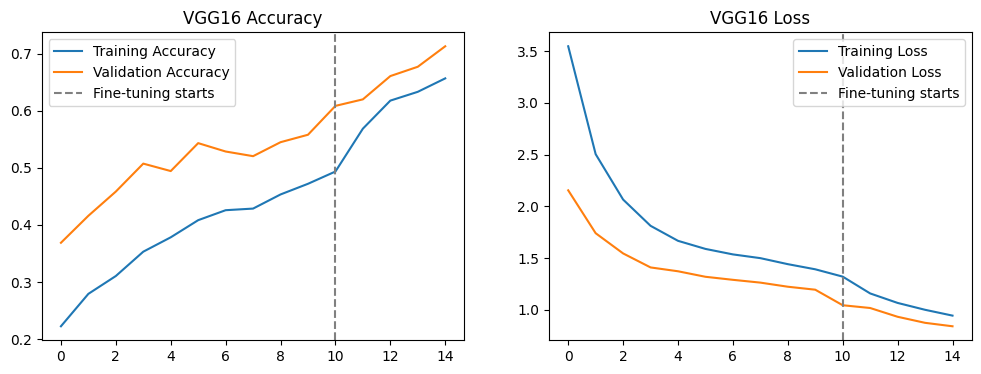

In [50]:
import matplotlib.pyplot as plt

acc = history_vgg16.history['accuracy'] + history_fine_tune.history['accuracy']
val_acc = history_vgg16.history['val_accuracy'] + history_fine_tune.history['val_accuracy']
loss = history_vgg16.history['loss'] + history_fine_tune.history['loss']
val_loss = history_vgg16.history['val_loss'] + history_fine_tune.history['val_loss']

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(EPOCHS, color='gray', linestyle='--', label='Fine-tuning starts')
plt.legend()
plt.title('VGG16 Accuracy')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(EPOCHS, color='gray', linestyle='--', label='Fine-tuning starts')
plt.legend()
plt.title('VGG16 Loss')

plt.show()

# Save Model

In [51]:
import os
from google.colab import drive

# Mount your Google Drive
drive.mount('/content/drive', force_remount=True)

# Use a DIFFERENT folder for saved models (not the dataset folder!)
model_dir = '/content/drive/MyDrive/Potato_Leaf_Disease_Models'

# Check if the directory exists, create if not
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Get the latest version for VGG16 specifically
existing_versions = [
    int(i.split('_v')[-1].split('.keras')[0])
    for i in os.listdir(model_dir)
    if i.startswith('vgg16_model_v') and i.split('_v')[-1].split('.keras')[0].isdigit()
]
model_version = max(existing_versions + [0]) + 1

# Save the VGG16 model
vgg16_model.save(os.path.join(model_dir, f"vgg16_model_v{model_version}.keras"))

print(f"VGG16 saved as vgg16_model_v{model_version}.keras in {model_dir}")

Mounted at /content/drive
VGG16 saved as vgg16_model_v1.keras in /content/drive/MyDrive/Potato_Leaf_Disease_Models


# MobileNetV2 Transfer Learning Model

# 1.MobileNetV2 and Build the Base Model

In [52]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMAGE_SIZE = 256
CHANNELS = 3
n_classes = 7

# Load MobileNetV2 pretrained on ImageNet, without the top classification layers
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
)

# Freeze the base model so pretrained weights aren't updated during initial training
base_model.trainable = False

/tmp/ipykernel_917/981923786.py:9: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


# 2. Preprocessing Layer for MobileNetV2

In [53]:
mobilenet_preprocess = tf.keras.layers.Lambda(preprocess_input)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])

# 3. Build the  Model

In [54]:
mobilenet_model = models.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    data_augmentation,
    mobilenet_preprocess,

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(n_classes, activation='softmax'),
])

mobilenet_model.build(input_shape=(None, IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
mobilenet_model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_2 (Resizing)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_5 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 8, 8, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,855 (9.24 MB)

 Trainable params: 164,871 (644.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# 4. Compile the Model

In [55]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# 5. Train

In [56]:
EPOCHS = 10

history_mobilenet = mobilenet_model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    verbose=1
)

Epoch 1/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 60s 693ms/step - accuracy: 0.2926 - loss: 1.8117 - val_accuracy: 0.3834 - val_loss: 1.5424
Epoch 2/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 54s 702ms/step - accuracy: 0.4391 - loss: 1.4634 - val_accuracy: 0.5106 - val_loss: 1.3649
Epoch 3/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 52s 676ms/step - accuracy: 0.5020 - loss: 1.3130 - val_accuracy: 0.5726 - val_loss: 1.2354
Epoch 4/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 82s 679ms/step - accuracy: 0.5495 - loss: 1.2247 - val_accuracy: 0.5987 - val_loss: 1.1779
Epoch 5/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 53s 692ms/step - accuracy: 0.5840 - loss: 1.1356 - val_accuracy: 0.6183 - val_loss: 1.1108
Epoch 6/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 52s 675ms/step - accuracy: 0.5942 - loss: 1.0868 - val_accuracy: 0.6623 - val_loss: 1.0422
Epoch 7/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 54s 703ms/step - accuracy: 0.6055 - loss: 1.0606 - val_accuracy: 0.6444 - val_loss: 1.0398
Epoch 8/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 52s 679ms/step - accuracy: 0.6258 - loss: 1.0169 - val_accu

# 6. Fine-Tune

In [57]:
# Unfreeze the base model
base_model.trainable = True

# MobileNetV2 has ~154 layers — unfreeze only the last ~30 for fine-tuning
fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Recompile with a much lower learning rate for fine-tuning
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

fine_tune_epochs = 5
total_epochs = EPOCHS + fine_tune_epochs

history_fine_tune = mobilenet_model.fit(
    train_ds,
    epochs=total_epochs,
    initial_epoch=history_mobilenet.epoch[-1] + 1,
    validation_data=val_ds,
    verbose=1
)

Epoch 11/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 67s 733ms/step - accuracy: 0.5471 - loss: 1.2004 - val_accuracy: 0.6215 - val_loss: 0.9889
Epoch 12/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 56s 738ms/step - accuracy: 0.6140 - loss: 1.0419 - val_accuracy: 0.5710 - val_loss: 1.0987
Epoch 13/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 65s 855ms/step - accuracy: 0.6189 - loss: 0.9981 - val_accuracy: 0.5644 - val_loss: 1.1039
Epoch 14/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 56s 727ms/step - accuracy: 0.6615 - loss: 0.9562 - val_accuracy: 0.5873 - val_loss: 1.0449
Epoch 15/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 56s 729ms/step - accuracy: 0.6761 - loss: 0.8879 - val_accuracy: 0.5742 - val_loss: 1.1006


# 7. Evaluate on Test Set

In [58]:
scores = mobilenet_model.evaluate(test_ds)
print("MobileNetV2 Test Loss:", scores[0])
print("MobileNetV2 Test Accuracy:", scores[1])

20/20 ━━━━━━━━━━━━━━━━━━━━ 30s 302ms/step - accuracy: 0.5808 - loss: 1.0763
MobileNetV2 Test Loss: 1.0762977600097656
MobileNetV2 Test Accuracy: 0.5807504057884216


# 8. Plot Training Curves

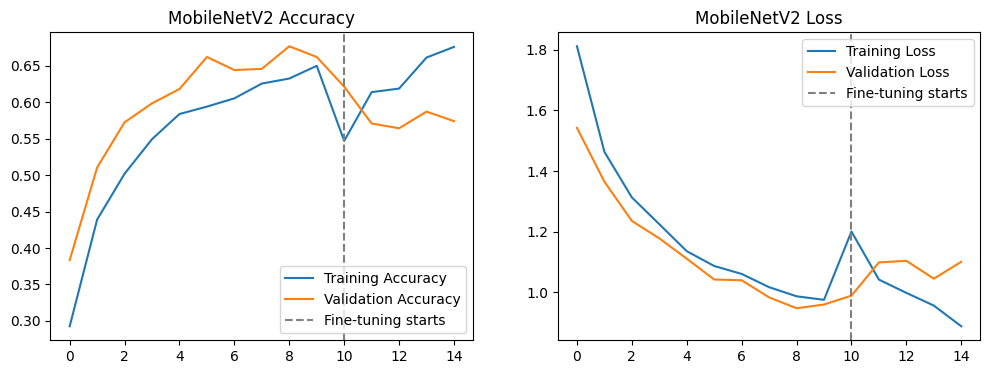

In [59]:
import matplotlib.pyplot as plt

acc = history_mobilenet.history['accuracy'] + history_fine_tune.history['accuracy']
val_acc = history_mobilenet.history['val_accuracy'] + history_fine_tune.history['val_accuracy']
loss = history_mobilenet.history['loss'] + history_fine_tune.history['loss']
val_loss = history_mobilenet.history['val_loss'] + history_fine_tune.history['val_loss']

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(EPOCHS, color='gray', linestyle='--', label='Fine-tuning starts')
plt.legend()
plt.title('MobileNetV2 Accuracy')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(EPOCHS, color='gray', linestyle='--', label='Fine-tuning starts')
plt.legend()
plt.title('MobileNetV2 Loss')

plt.show()

# Save Model

In [60]:
import os
from google.colab import drive

# Mount your Google Drive
drive.mount('/content/drive', force_remount=True)

# Use a DIFFERENT folder for saved models (not the dataset folder!)
model_dir = '/content/drive/MyDrive/Potato_Leaf_Disease_Models'

# Check if the directory exists, create if not
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Get the latest version for MobileNetV2 specifically
existing_versions = [
    int(i.split('_v')[-1].split('.keras')[0])
    for i in os.listdir(model_dir)
    if i.startswith('mobilenet_v2_model_v') and i.split('_v')[-1].split('.keras')[0].isdigit()
]
model_version = max(existing_versions + [0]) + 1

# Save the MobileNetV2 model
mobilenet_model.save(os.path.join(model_dir, f"mobilenet_v2_model_v{model_version}.keras"))

print(f"MobileNetV2 saved as mobilenet_v2_model_v{model_version}.keras in {model_dir}")

Mounted at /content/drive
MobileNetV2 saved as mobilenet_v2_model_v1.keras in /content/drive/MyDrive/Potato_Leaf_Disease_Models


# MODEL COMPARISON: Custom CNN vs VGG16 vs MobileNetV2

# 1. Collect Test Set Performance

In [61]:
# Assumes model, vgg16_model, mobilenet_model and their histories already exist
# and test_ds / EPOCHS are the same across all three

cnn_scores = model.evaluate(test_ds, verbose=0)
vgg16_scores = vgg16_model.evaluate(test_ds, verbose=0)
mobilenet_scores = mobilenet_model.evaluate(test_ds, verbose=0)

results = {
    "Custom CNN": {"Test Loss": cnn_scores[0], "Test Accuracy": cnn_scores[1]},
    "VGG16": {"Test Loss": vgg16_scores[0], "Test Accuracy": vgg16_scores[1]},
    "MobileNetV2": {"Test Loss": mobilenet_scores[0], "Test Accuracy": mobilenet_scores[1]},
}

import pandas as pd
results_df = pd.DataFrame(results).T
results_df["Test Accuracy (%)"] = (results_df["Test Accuracy"] * 100).round(2)
results_df = results_df[["Test Loss", "Test Accuracy (%)"]]
print(results_df)

             Test Loss  Test Accuracy (%)
Custom CNN    1.546262              35.24
VGG16         0.808349              72.27
MobileNetV2   1.088113              58.08


# 2. Parameter Count Comparison

In [62]:
model_params = {
    "Custom CNN": model.count_params(),
    "VGG16": vgg16_model.count_params(),
    "MobileNetV2": mobilenet_model.count_params(),
}

params_df = pd.DataFrame.from_dict(model_params, orient='index', columns=['Total Parameters'])
params_df['Total Parameters (M)'] = (params_df['Total Parameters'] / 1_000_000).round(2)
print(params_df)

             Total Parameters  Total Parameters (M)
Custom CNN             184007                  0.18
VGG16                14781255                 14.78
MobileNetV2           2422855                  2.42


# 3. Combined Metrics Table

In [63]:
comparison_df = results_df.join(params_df[['Total Parameters (M)']])
print(comparison_df)

# Optional: save for the report
comparison_df.to_csv('model_comparison_results.csv')

             Test Loss  Test Accuracy (%)  Total Parameters (M)
Custom CNN    1.546262              35.24                  0.18
VGG16         0.808349              72.27                 14.78
MobileNetV2   1.088113              58.08                  2.42


# 4. Side-by-Side Training Curves

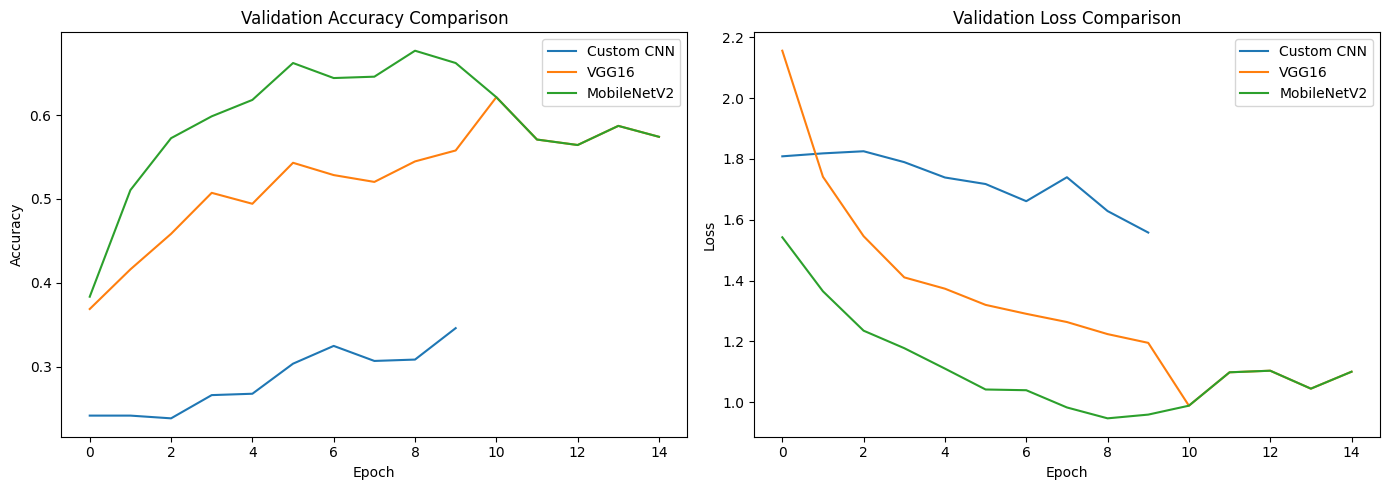

In [64]:
import matplotlib.pyplot as plt

# Build full accuracy/loss histories (frozen phase + fine-tuning phase)
cnn_acc = history.history['accuracy']
cnn_val_acc = history.history['val_accuracy']

vgg_acc = history_vgg16.history['accuracy'] + history_fine_tune.history['accuracy']
vgg_val_acc = history_vgg16.history['val_accuracy'] + history_fine_tune.history['val_accuracy']

mob_acc = history_mobilenet.history['accuracy'] + history_fine_tune.history['accuracy']
mob_val_acc = history_mobilenet.history['val_accuracy'] + history_fine_tune.history['val_accuracy']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(cnn_val_acc, label='Custom CNN')
axes[0].plot(vgg_val_acc, label='VGG16')
axes[0].plot(mob_val_acc, label='MobileNetV2')
axes[0].set_title('Validation Accuracy Comparison')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

cnn_val_loss = history.history['val_loss']
vgg_val_loss = history_vgg16.history['val_loss'] + history_fine_tune.history['val_loss']
mob_val_loss = history_mobilenet.history['val_loss'] + history_fine_tune.history['val_loss']

axes[1].plot(cnn_val_loss, label='Custom CNN')
axes[1].plot(vgg_val_loss, label='VGG16')
axes[1].plot(mob_val_loss, label='MobileNetV2')
axes[1].set_title('Validation Loss Comparison')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

# 5. Confusion Matrices Side by Side

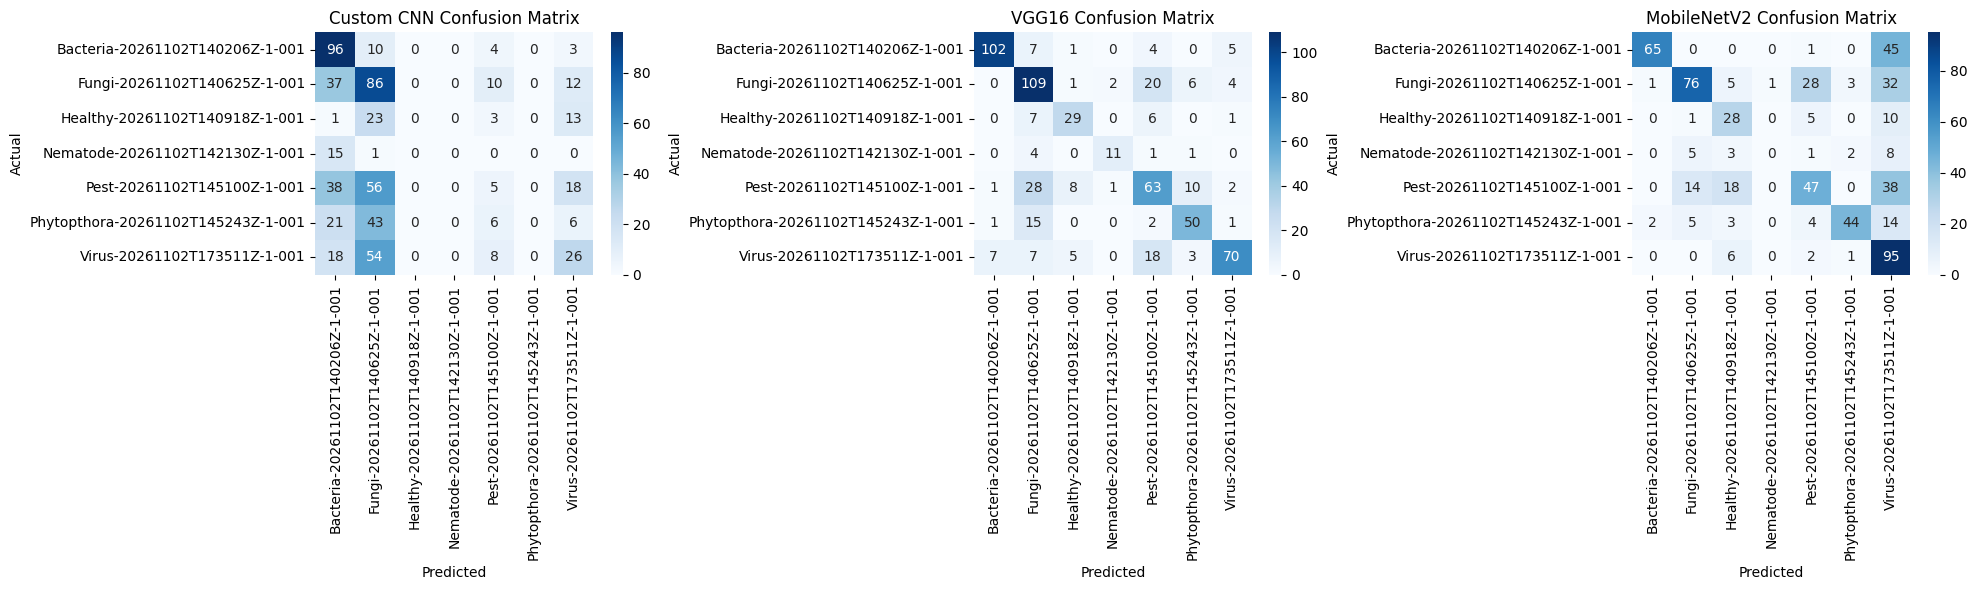

In [65]:
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

def get_true_and_predicted(model, dataset):
    y_true, y_pred = [], []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(preds, axis=1))
    return np.array(y_true), np.array(y_pred)

cnn_true, cnn_pred = get_true_and_predicted(model, test_ds)
vgg_true, vgg_pred = get_true_and_predicted(vgg16_model, test_ds)
mob_true, mob_pred = get_true_and_predicted(mobilenet_model, test_ds)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (name, y_true, y_pred) in zip(
    axes,
    [("Custom CNN", cnn_true, cnn_pred),
     ("VGG16", vgg_true, vgg_pred),
     ("MobileNetV2", mob_true, mob_pred)]
):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=ClassNames, yticklabels=ClassNames, ax=ax)
    ax.set_title(f'{name} Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

# 6. Classification Reports (Precision, Recall, F1)

In [66]:
from sklearn.metrics import classification_report

print("Custom CNN Classification Report")
print(classification_report(cnn_true, cnn_pred, target_names=ClassNames))

print("\nVGG16 Classification Report")
print(classification_report(vgg_true, vgg_pred, target_names=ClassNames))

print("\nMobileNetV2 Classification Report")
print(classification_report(mob_true, mob_pred, target_names=ClassNames))

Custom CNN Classification Report
                                    precision    recall  f1-score   support

   Bacteria-20261102T140206Z-1-001       0.42      0.85      0.57       113
      Fungi-20261102T140625Z-1-001       0.32      0.59      0.41       145
    Healthy-20261102T140918Z-1-001       0.00      0.00      0.00        40
   Nematode-20261102T142130Z-1-001       0.00      0.00      0.00        16
       Pest-20261102T145100Z-1-001       0.14      0.04      0.07       117
Phytopthora-20261102T145243Z-1-001       0.00      0.00      0.00        76
      Virus-20261102T173511Z-1-001       0.33      0.25      0.28       106

                          accuracy                           0.35       613
                         macro avg       0.17      0.25      0.19       613
                      weighted avg       0.24      0.35      0.26       613


VGG16 Classification Report
                                    precision    recall  f1-score   support

   Bacteria-20261102T1

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# 7. Final Comparison Bar Chart

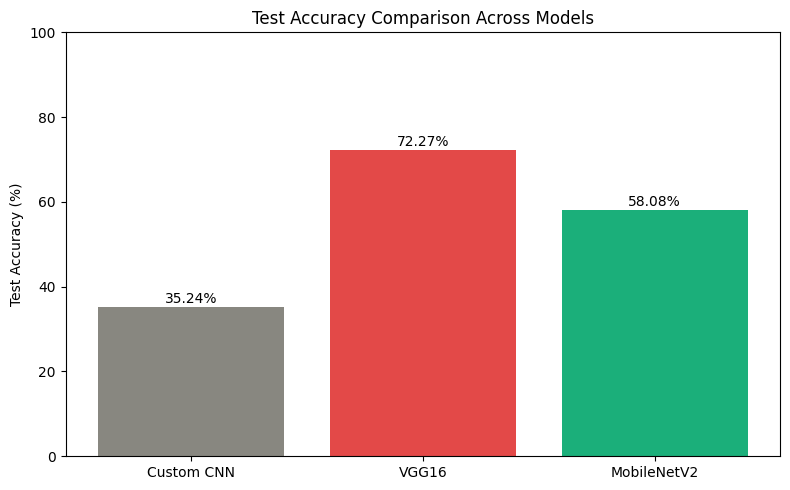

In [67]:
fig, ax = plt.subplots(figsize=(8, 5))
models_list = list(results.keys())
accuracies = [results[m]["Test Accuracy"] * 100 for m in models_list]

bars = ax.bar(models_list, accuracies, color=['#888780', '#e34948', '#1baf7a'])
ax.set_ylabel('Test Accuracy (%)')
ax.set_title('Test Accuracy Comparison Across Models')
ax.set_ylim(0, 100)

for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{acc:.2f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()